In [ ]:
!pip install nltk spacy gensim wordcloud matplotlib -q

In [ ]:
import nltk
import string
import re
from collections import Counter

import matplotlib.pyplot as plt
from wordcloud import WordCloud

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

from gensim.models import Word2Vec

# Download required NLTK datasets
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [ ]:
original_text = """
Sustainability is an important concept that focuses on meeting the needs of the present
without compromising the ability of future generations to meet their own needs. A
sustainable society uses natural resources carefully and reduces activities that damage
the environment. Climate change, pollution, deforestation, loss of biodiversity, and
excessive consumption have increased the need for sustainable development around the
world. Individuals, businesses, governments, and educational institutions all have an
important role in creating a more sustainable future.

Renewable energy sources such as solar energy, wind energy, and hydropower can reduce
dependence on fossil fuels and decrease greenhouse gas emissions. Sustainable
transportation, including public transport, electric vehicles, cycling, and walking, can
also reduce air pollution and energy consumption. Recycling, reusing materials, and
reducing waste help conserve valuable natural resources. Communities can promote
sustainability by using efficient technologies, supporting local products, protecting
forests and water resources, and encouraging responsible consumption.

Education is also essential for sustainability because it helps people understand the
environmental, social, and economic consequences of their decisions. Students and
citizens can contribute by saving electricity, reducing plastic use, conserving water,
and choosing environmentally responsible products. Businesses can adopt sustainable
production methods and develop innovative technologies that reduce waste and improve
efficiency. Governments can create policies that support clean energy, environmental
protection, and sustainable development. Through cooperation, innovation, awareness,
and responsible decision making, society can build a healthier environment and create
a more sustainable future for present and future generations.
"""

print("Original Text:\n")
print(original_text)

Original Text:


Sustainability is an important concept that focuses on meeting the needs of the present
without compromising the ability of future generations to meet their own needs. A
sustainable society uses natural resources carefully and reduces activities that damage
the environment. Climate change, pollution, deforestation, loss of biodiversity, and
excessive consumption have increased the need for sustainable development around the
world. Individuals, businesses, governments, and educational institutions all have an
important role in creating a more sustainable future.

Renewable energy sources such as solar energy, wind energy, and hydropower can reduce
dependence on fossil fuels and decrease greenhouse gas emissions. Sustainable
transportation, including public transport, electric vehicles, cycling, and walking, can
also reduce air pollution and energy consumption. Recycling, reusing materials, and
reducing waste help conserve valuable natural resources. Communities can prom

In [ ]:
lowercase_text = original_text.lower()

print("Lowercase Text:\n")
print(lowercase_text)

Lowercase Text:


sustainability is an important concept that focuses on meeting the needs of the present
without compromising the ability of future generations to meet their own needs. a
sustainable society uses natural resources carefully and reduces activities that damage
the environment. climate change, pollution, deforestation, loss of biodiversity, and
excessive consumption have increased the need for sustainable development around the
world. individuals, businesses, governments, and educational institutions all have an
important role in creating a more sustainable future.

renewable energy sources such as solar energy, wind energy, and hydropower can reduce
dependence on fossil fuels and decrease greenhouse gas emissions. sustainable
transportation, including public transport, electric vehicles, cycling, and walking, can
also reduce air pollution and energy consumption. recycling, reusing materials, and
reducing waste help conserve valuable natural resources. communities can pro

In [ ]:
# Remove punctuation and special characters
cleaned_text = re.sub(r'[^a-zA-Z\s]', '', lowercase_text)

print("Cleaned Text:\n")
print(cleaned_text)

Cleaned Text:


sustainability is an important concept that focuses on meeting the needs of the present
without compromising the ability of future generations to meet their own needs a
sustainable society uses natural resources carefully and reduces activities that damage
the environment climate change pollution deforestation loss of biodiversity and
excessive consumption have increased the need for sustainable development around the
world individuals businesses governments and educational institutions all have an
important role in creating a more sustainable future

renewable energy sources such as solar energy wind energy and hydropower can reduce
dependence on fossil fuels and decrease greenhouse gas emissions sustainable
transportation including public transport electric vehicles cycling and walking can
also reduce air pollution and energy consumption recycling reusing materials and
reducing waste help conserve valuable natural resources communities can promote
sustainability by us

In [ ]:
tokens = word_tokenize(cleaned_text)

print("Total number of tokens:", len(tokens))
print("\nToken List:\n")
print(tokens)

Total number of tokens: 240

Token List:

['sustainability', 'is', 'an', 'important', 'concept', 'that', 'focuses', 'on', 'meeting', 'the', 'needs', 'of', 'the', 'present', 'without', 'compromising', 'the', 'ability', 'of', 'future', 'generations', 'to', 'meet', 'their', 'own', 'needs', 'a', 'sustainable', 'society', 'uses', 'natural', 'resources', 'carefully', 'and', 'reduces', 'activities', 'that', 'damage', 'the', 'environment', 'climate', 'change', 'pollution', 'deforestation', 'loss', 'of', 'biodiversity', 'and', 'excessive', 'consumption', 'have', 'increased', 'the', 'need', 'for', 'sustainable', 'development', 'around', 'the', 'world', 'individuals', 'businesses', 'governments', 'and', 'educational', 'institutions', 'all', 'have', 'an', 'important', 'role', 'in', 'creating', 'a', 'more', 'sustainable', 'future', 'renewable', 'energy', 'sources', 'such', 'as', 'solar', 'energy', 'wind', 'energy', 'and', 'hydropower', 'can', 'reduce', 'dependence', 'on', 'fossil', 'fuels', 'and', 

In [ ]:
stop_words = set(stopwords.words('english'))

processed_tokens = [
    word for word in tokens
    if word.isalpha() and word not in stop_words
]

print("Number of tokens after stop-word removal:", len(processed_tokens))
print("\nProcessed Tokens:\n")
print(processed_tokens)

Number of tokens after stop-word removal: 169

Processed Tokens:

['sustainability', 'important', 'concept', 'focuses', 'meeting', 'needs', 'present', 'without', 'compromising', 'ability', 'future', 'generations', 'meet', 'needs', 'sustainable', 'society', 'uses', 'natural', 'resources', 'carefully', 'reduces', 'activities', 'damage', 'environment', 'climate', 'change', 'pollution', 'deforestation', 'loss', 'biodiversity', 'excessive', 'consumption', 'increased', 'need', 'sustainable', 'development', 'around', 'world', 'individuals', 'businesses', 'governments', 'educational', 'institutions', 'important', 'role', 'creating', 'sustainable', 'future', 'renewable', 'energy', 'sources', 'solar', 'energy', 'wind', 'energy', 'hydropower', 'reduce', 'dependence', 'fossil', 'fuels', 'decrease', 'greenhouse', 'gas', 'emissions', 'sustainable', 'transportation', 'including', 'public', 'transport', 'electric', 'vehicles', 'cycling', 'walking', 'also', 'reduce', 'air', 'pollution', 'energy', 'cons

In [ ]:
stemmer = PorterStemmer()

stemmed_words = [
    stemmer.stem(word)
    for word in processed_tokens
]

print("Stemmed Words:\n")
print(stemmed_words)

Stemmed Words:

['sustain', 'import', 'concept', 'focus', 'meet', 'need', 'present', 'without', 'compromis', 'abil', 'futur', 'gener', 'meet', 'need', 'sustain', 'societi', 'use', 'natur', 'resourc', 'care', 'reduc', 'activ', 'damag', 'environ', 'climat', 'chang', 'pollut', 'deforest', 'loss', 'biodivers', 'excess', 'consumpt', 'increas', 'need', 'sustain', 'develop', 'around', 'world', 'individu', 'busi', 'govern', 'educ', 'institut', 'import', 'role', 'creat', 'sustain', 'futur', 'renew', 'energi', 'sourc', 'solar', 'energi', 'wind', 'energi', 'hydropow', 'reduc', 'depend', 'fossil', 'fuel', 'decreas', 'greenhous', 'ga', 'emiss', 'sustain', 'transport', 'includ', 'public', 'transport', 'electr', 'vehicl', 'cycl', 'walk', 'also', 'reduc', 'air', 'pollut', 'energi', 'consumpt', 'recycl', 'reus', 'materi', 'reduc', 'wast', 'help', 'conserv', 'valuabl', 'natur', 'resourc', 'commun', 'promot', 'sustain', 'use', 'effici', 'technolog', 'support', 'local', 'product', 'protect', 'forest', 'wa

In [ ]:
lemmatizer = WordNetLemmatizer()

lemmatized_words = [
    lemmatizer.lemmatize(word)
    for word in processed_tokens
]

print("Lemmatized Words:\n")
print(lemmatized_words)

Lemmatized Words:

['sustainability', 'important', 'concept', 'focus', 'meeting', 'need', 'present', 'without', 'compromising', 'ability', 'future', 'generation', 'meet', 'need', 'sustainable', 'society', 'us', 'natural', 'resource', 'carefully', 'reduces', 'activity', 'damage', 'environment', 'climate', 'change', 'pollution', 'deforestation', 'loss', 'biodiversity', 'excessive', 'consumption', 'increased', 'need', 'sustainable', 'development', 'around', 'world', 'individual', 'business', 'government', 'educational', 'institution', 'important', 'role', 'creating', 'sustainable', 'future', 'renewable', 'energy', 'source', 'solar', 'energy', 'wind', 'energy', 'hydropower', 'reduce', 'dependence', 'fossil', 'fuel', 'decrease', 'greenhouse', 'gas', 'emission', 'sustainable', 'transportation', 'including', 'public', 'transport', 'electric', 'vehicle', 'cycling', 'walking', 'also', 'reduce', 'air', 'pollution', 'energy', 'consumption', 'recycling', 'reusing', 'material', 'reducing', 'waste',

In [ ]:
print("ORIGINAL TOKENS:\n")
print(tokens[:50])

print("\nPREPROCESSED TOKENS:\n")
print(processed_tokens[:50])

print("\nSTEMMED WORDS:\n")
print(stemmed_words[:50])

print("\nLEMMATIZED WORDS:\n")
print(lemmatized_words[:50])

ORIGINAL TOKENS:

['sustainability', 'is', 'an', 'important', 'concept', 'that', 'focuses', 'on', 'meeting', 'the', 'needs', 'of', 'the', 'present', 'without', 'compromising', 'the', 'ability', 'of', 'future', 'generations', 'to', 'meet', 'their', 'own', 'needs', 'a', 'sustainable', 'society', 'uses', 'natural', 'resources', 'carefully', 'and', 'reduces', 'activities', 'that', 'damage', 'the', 'environment', 'climate', 'change', 'pollution', 'deforestation', 'loss', 'of', 'biodiversity', 'and', 'excessive', 'consumption']

PREPROCESSED TOKENS:

['sustainability', 'important', 'concept', 'focuses', 'meeting', 'needs', 'present', 'without', 'compromising', 'ability', 'future', 'generations', 'meet', 'needs', 'sustainable', 'society', 'uses', 'natural', 'resources', 'carefully', 'reduces', 'activities', 'damage', 'environment', 'climate', 'change', 'pollution', 'deforestation', 'loss', 'biodiversity', 'excessive', 'consumption', 'increased', 'need', 'sustainable', 'development', 'around',

In [ ]:
word_frequency = Counter(lemmatized_words)

print("Top 20 Most Frequent Words:\n")

for word, frequency in word_frequency.most_common(20):
    print(word, ":", frequency)

Top 20 Most Frequent Words:

sustainable : 7
energy : 5
future : 4
sustainability : 3
need : 3
resource : 3
consumption : 3
reduce : 3
responsible : 3
important : 2
present : 2
generation : 2
society : 2
natural : 2
environment : 2
pollution : 2
development : 2
business : 2
government : 2
also : 2


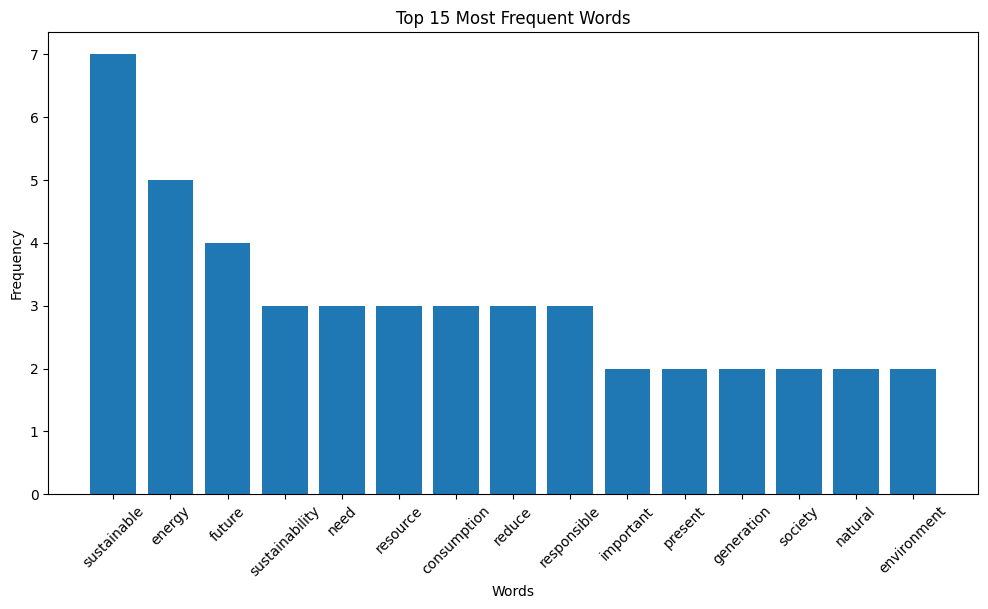

In [ ]:
top_words = word_frequency.most_common(15)

words = [item[0] for item in top_words]
frequencies = [item[1] for item in top_words]

plt.figure(figsize=(12, 6))
plt.bar(words, frequencies)
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.title("Top 15 Most Frequent Words")
plt.xticks(rotation=45)
plt.show()

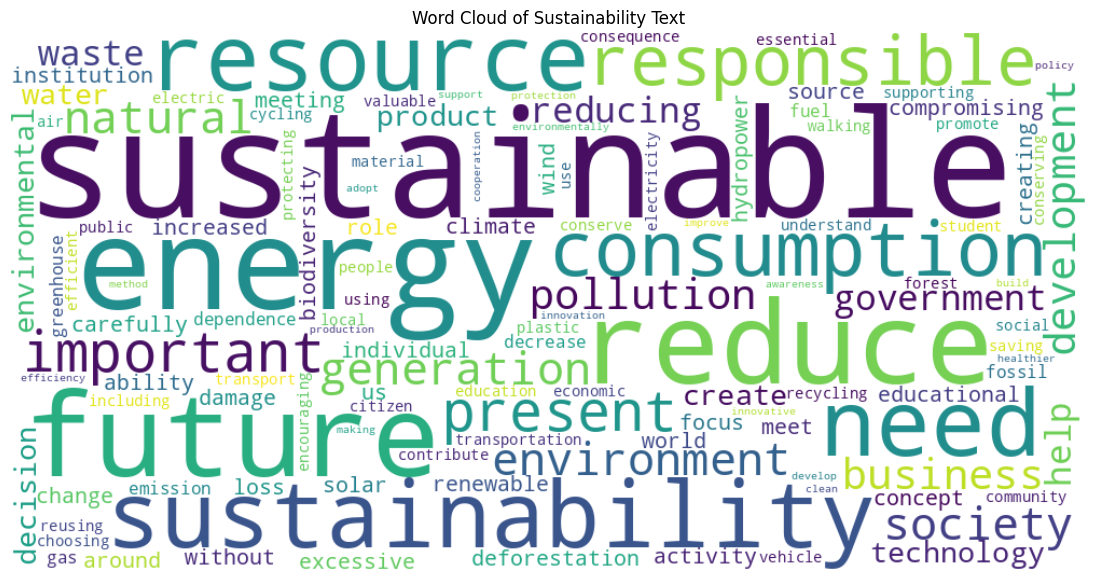

In [ ]:
processed_text = " ".join(lemmatized_words)

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(processed_text)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Sustainability Text")
plt.show()

In [ ]:
from nltk.tokenize import sent_tokenize

sentences = sent_tokenize(original_text.lower())

training_data = []

for sentence in sentences:

    # Remove special characters
    sentence = re.sub(r'[^a-zA-Z\s]', '', sentence)

    # Tokenize
    words = word_tokenize(sentence)

    # Remove stop words
    words = [
        word for word in words
        if word.isalpha() and word not in stop_words
    ]

    if len(words) > 0:
        training_data.append(words)

print("Training Data for Word2Vec:\n")

for sentence in training_data:
    print(sentence)

Training Data for Word2Vec:

['sustainability', 'important', 'concept', 'focuses', 'meeting', 'needs', 'present', 'without', 'compromising', 'ability', 'future', 'generations', 'meet', 'needs']
['sustainable', 'society', 'uses', 'natural', 'resources', 'carefully', 'reduces', 'activities', 'damage', 'environment']
['climate', 'change', 'pollution', 'deforestation', 'loss', 'biodiversity', 'excessive', 'consumption', 'increased', 'need', 'sustainable', 'development', 'around', 'world']
['individuals', 'businesses', 'governments', 'educational', 'institutions', 'important', 'role', 'creating', 'sustainable', 'future']
['renewable', 'energy', 'sources', 'solar', 'energy', 'wind', 'energy', 'hydropower', 'reduce', 'dependence', 'fossil', 'fuels', 'decrease', 'greenhouse', 'gas', 'emissions']
['sustainable', 'transportation', 'including', 'public', 'transport', 'electric', 'vehicles', 'cycling', 'walking', 'also', 'reduce', 'air', 'pollution', 'energy', 'consumption']
['recycling', 'reusing

In [ ]:
word2vec_model = Word2Vec(
    sentences=training_data,
    vector_size=50,
    window=5,
    min_count=1,
    workers=4,
    sg=1,
    epochs=200
)

print("Word2Vec model created successfully!")

print("\nVocabulary Size:", len(word2vec_model.wv.key_to_index))

Word2Vec model created successfully!

Vocabulary Size: 127


In [ ]:
selected_words = [
    "sustainability",
    "environment",
    "energy",
    "development",
    "future"
]

for word in selected_words:

    if word in word2vec_model.wv:
        print(f"\nEmbedding vector for '{word}':")
        print(word2vec_model.wv[word])
    else:
        print(f"\n'{word}' is not available in the vocabulary.")


Embedding vector for 'sustainability':
[ 0.1539933  -0.09041538 -0.15817718 -0.25520882 -0.0845453  -0.31183025
  0.15592736  0.3350815  -0.10901681 -0.11582921  0.01141961 -0.25547805
  0.22323626  0.3080543  -0.08074539  0.04218852  0.00725146  0.13204111
 -0.41406277 -0.14535978  0.30651766  0.14394818  0.5369163  -0.09673214
  0.25027528 -0.14467312 -0.08792467 -0.05542356 -0.27964124  0.10037877
  0.04092082 -0.09629984 -0.02966314 -0.0822175  -0.0527559  -0.05127519
  0.26250818  0.15954308 -0.03183643  0.06942341  0.1490373  -0.07866287
  0.16328229 -0.19544733  0.41289747  0.0727293  -0.0494407  -0.1115906
  0.0775613  -0.00087813]

Embedding vector for 'environment':
[ 0.13987865 -0.05473896  0.008616   -0.18819894  0.01635117 -0.3150826
  0.16615999  0.40231735 -0.1881952  -0.09198078  0.02157129 -0.24599361
  0.07568721  0.26580775  0.00169989  0.10011095  0.03947229  0.14406887
 -0.3619948  -0.1709517   0.16560718  0.13088998  0.5676148  -0.20083582
  0.17578451 -0.0764861

In [ ]:
for word in selected_words:

    if word in word2vec_model.wv:
        vector = word2vec_model.wv[word]

        print(f"\nWord: {word}")
        print("First 10 vector values:")
        print(vector[:10])


Word: sustainability
First 10 vector values:
[ 0.1539933  -0.09041538 -0.15817718 -0.25520882 -0.0845453  -0.31183025
  0.15592736  0.3350815  -0.10901681 -0.11582921]

Word: environment
First 10 vector values:
[ 0.13987865 -0.05473896  0.008616   -0.18819894  0.01635117 -0.3150826
  0.16615999  0.40231735 -0.1881952  -0.09198078]

Word: energy
First 10 vector values:
[-0.00884553  0.03025808 -0.29719144 -0.17964873  0.3865103  -0.41607538
  0.00173547  0.21382076 -0.35534298  0.0066131 ]

Word: development
First 10 vector values:
[ 0.05033848 -0.11994561 -0.10337429 -0.09420272  0.07414891 -0.41403058
  0.14067145  0.27871794 -0.14386773 -0.084819  ]

Word: future
First 10 vector values:
[ 0.14793001  0.00943307  0.0330052  -0.20240463 -0.00208351 -0.3355297
  0.18601231  0.41029152 -0.12694415 -0.02974399]


In [ ]:
keyword = "sustainability"

if keyword in word2vec_model.wv:

    similar_words = word2vec_model.wv.most_similar(
        keyword,
        topn=3
    )

    print(f"Three words most similar to '{keyword}':\n")

    for word, similarity in similar_words:
        print(f"{word}: {similarity:.4f}")

else:
    print(f"{keyword} is not available in the vocabulary.")

Three words most similar to 'sustainability':

communities: 0.9639
decisions: 0.9637
consequences: 0.9631


In [ ]:
keywords = [
    "sustainability",
    "environment",
    "energy",
    "water",
    "future"
]

for keyword in keywords:

    if keyword in word2vec_model.wv:

        print(f"\nTop 3 words similar to '{keyword}':")

        similar_words = word2vec_model.wv.most_similar(
            keyword,
            topn=3
        )

        for word, similarity in similar_words:
            print(f"{word}: {similarity:.4f}")


Top 3 words similar to 'sustainability':
communities: 0.9639
decisions: 0.9637
consequences: 0.9631

Top 3 words similar to 'environment':
society: 0.9963
awareness: 0.9894
decision: 0.9893

Top 3 words similar to 'energy':
dependence: 0.9927
wind: 0.9913
hydropower: 0.9908

Top 3 words similar to 'water':
products: 0.9895
environmentally: 0.9803
choosing: 0.9764

Top 3 words similar to 'future':
generations: 0.9887
present: 0.9879
healthier: 0.9819


In [ ]:
word1 = "sustainability"
word2 = "environment"

if word1 in word2vec_model.wv and word2 in word2vec_model.wv:

    similarity_score = word2vec_model.wv.similarity(
        word1,
        word2
    )

    print(
        f"Similarity between '{word1}' and '{word2}': "
        f"{similarity_score:.4f}"
    )

Similarity between 'sustainability' and 'environment': 0.9088


In [ ]:
print("=" * 60)
print("NLP TEXT PREPROCESSING AND WORD EMBEDDING RESULTS")
print("=" * 60)

print("\n1. Original word count:", len(word_tokenize(original_text)))
print("2. Processed word count:", len(processed_tokens))
print("3. Number of unique processed words:", len(set(processed_tokens)))
print("4. Word2Vec vocabulary size:", len(word2vec_model.wv.key_to_index))

print("\nTop 10 Frequent Words:")

for word, frequency in word_frequency.most_common(10):
    print(f"{word}: {frequency}")



NLP TEXT PREPROCESSING AND WORD EMBEDDING RESULTS

1. Original word count: 283
2. Processed word count: 169
3. Number of unique processed words: 127
4. Word2Vec vocabulary size: 127

Top 10 Frequent Words:
sustainable: 7
energy: 5
future: 4
sustainability: 3
need: 3
resource: 3
consumption: 3
reduce: 3
responsible: 3
important: 2


## Explanation of NLP Text Preprocessing and Word Embedding

This notebook demonstrates a typical workflow for Natural Language Processing (NLP) text preprocessing and the creation of word embeddings using Word2Vec.

### 1. Text Preprocessing Steps:

1.  **Original Text Loading:** The initial text data is loaded from a multiline string variable `original_text`.
2.  **Lowercasing:** All text is converted to lowercase to ensure consistency and prevent the same word from being treated as different tokens due to capitalization (e.g., 'Sustainability' vs. 'sustainability').
3.  **Punctuation and Special Character Removal:** Regular expressions (`re.sub(r'[^a-zA-Z\s]', '', lowercase_text)`) are used to remove all characters that are not letters or spaces. This helps to clean the text and focus on the actual words.
4.  **Tokenization:** The `nltk.word_tokenize` function is used to break down the cleaned text into individual words or tokens. This is a fundamental step for any text analysis.
5.  **Stop Word Removal:** Common English stop words (e.g., 'is', 'an', 'the') are removed using `nltk.corpus.stopwords`. These words often carry little semantic meaning and can clutter the analysis. The `processed_tokens` list contains words that are alphabetic and not in the stop words set.
6.  **Stemming (Demonstration):** The `PorterStemmer` from NLTK is used to reduce words to their base or root form (e.g., 'reducing' becomes 'reduc'). This process is generally more aggressive and might not always result in a valid word.
7.  **Lemmatization (Applied to `lemmatized_words`):** The `WordNetLemmatizer` from NLTK is used to reduce words to their base or dictionary form (e.g., 'reducing' becomes 'reduce'). Unlike stemming, lemmatization usually results in a valid word, which is often preferred for maintaining semantic meaning. For the subsequent Word2Vec model, `lemmatized_words` were used to create the word frequency and word cloud.

### 2. Word Frequency and Visualization:

-   **Word Frequency Counter:** The `collections.Counter` object is used on the `lemmatized_words` to count the occurrences of each word. The top 20 most frequent words are then displayed.
-   **Bar Chart:** A bar chart visualizes the top 15 most frequent words and their counts.
-   **Word Cloud:** A `WordCloud` is generated from the `processed_text` (which is the joined `lemmatized_words`) to visually represent word frequency, where larger words indicate higher frequency.

### 3. Word2Vec Embedding:

-   **Training Data Preparation:** The `original_text` is first tokenized into sentences (`sent_tokenize`). Each sentence is then cleaned (punctuation removed, lowercased, tokenized, and stop words removed) to form the `training_data` for the Word2Vec model. This ensures that the model learns word relationships within sentence contexts.
-   **Word2Vec Model Creation:**
    -   The `gensim.models.Word2Vec` model is initialized and trained on the `training_data`.
    -   **Parameters Used:**
        -   `sentences=training_data`: The preprocessed list of sentences.
        -   `vector_size=50`: Each word will be represented by a 50-dimensional vector. This determines the richness of the word representation.
        -   `window=5`: The maximum distance between the current and predicted word within a sentence. A window of 5 means the model considers 5 words before and 5 words after the target word.
        -   `min_count=1`: Words that appear less than this count are ignored. Setting it to 1 means all words in the `training_data` are considered.
        -   `workers=4`: Uses 4 CPU cores for training, speeding up the process.
        -   `sg=1`: Specifies the training algorithm. `sg=1` indicates the Skip-gram model, which is generally better for infrequent words and learns richer representations than CBOW (`sg=0`).
        -   `epochs=200`: The number of iterations (epochs) over the corpus. More epochs can lead to better quality embeddings but also increase training time.
-   **Vocabulary Size:** The size of the Word2Vec model's vocabulary (`word2vec_model.wv.key_to_index`) is printed, indicating how many unique words the model learned embeddings for.
-   **Word Vector Retrieval:** The embedding vectors for selected words ("sustainability", "environment", "energy", "development", "future") are retrieved and displayed. The first 10 values of each vector are shown as an example.
-   **Finding Similar Words:** The `word2vec_model.wv.most_similar(word, topn=3)` method is used to find the top 3 most semantically similar words to a given keyword, based on the cosine similarity of their embedding vectors.
-   **Calculating Word Similarity:** The `word2vec_model.wv.similarity(word1, word2)` method calculates the cosine similarity between the embedding vectors of two specified words, providing a numerical measure of their semantic relatedness.